In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchdiffeq import odeint

We start by constructing the velocity field with conditional probability path.

In [24]:
# get velocity field u_t(x|x_1)
def conditional_field(position, time, target, sigmin):
    return (target-(1-sigmin)*position)/(1-(1-sigmin)*time)

# get flow psi_t(x)
def conditional_sample(noise, time, target, sigmin):
    sigma = 1-(1-sigmin)*time
    mean = time*target
    return sigma*noise + mean

## 1-D Flow Matching


In [ ]:
Sigmin = 0.01 # sigma_min

# get random coordinates of the velocity field
def get_batch(N=1000):
    positions = np.random.uniform(-1, 1, N)
    times = np.random.uniform(0, 1, N)
    xt = np.column_stack([positions, times])
    return xt

### Visualization of a conditional field in 1D

Let's see how a conditional field with one target looks like:

(-1.0, 1.0)

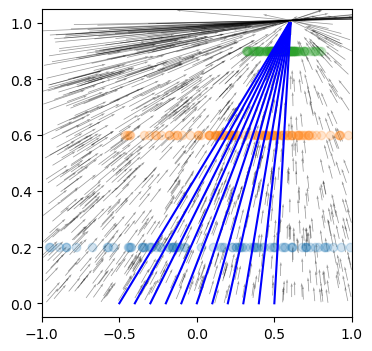

In [51]:
Target = 0.6 # x_1 for conditional FM

# generate coordinates of the velocity field
xt = get_batch(1000)
target = np.full_like(xt[:,0], Target) # generate a list of the same target
field_test = conditional_field(xt[:,0], xt[:,1], target, Sigmin) # construct a cond field
plt.quiver(xt[:,0], xt[:,1], field_test, np.ones_like(field_test), angles='xy', scale_units = 'xy', scale = 20, alpha = 0.4)

# calculate examples of cond probability paths with odeint
tint = np.linspace(0.0,1.0)
xint = odeint(lambda t, x:conditional_field(x, t, Target, Sigmin), torch.tensor(np.linspace(-0.5,0.5,11).reshape(-1, 1)), torch.tensor(tint))
xint, tint = np.broadcast_arrays(xint, tint.reshape(-1,1,1)) # broadcasting extends tint from (50,1,1) to (50,11,1), matching xint
plt.plot(xint[...,0], tint[...,0], c='b') # plot cond prob paths

# draw samples at different times
noise = torch.randn(100)
for t in [0.2, 0.6, 0.9]:
    sample = conditional_sample(noise, t, Target, Sigmin)
    plt.scatter(sample, np.full_like(sample, t), alpha=0.2)

plt.gcf().set_size_inches(4,4)
plt.xlim(-1, 1)

### Training

In [77]:
def sample_data(N=100):
    return torch.tensor(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=N), scale=0.1))

def mlp(hidden=128):
    return torch.nn.Sequential(
        torch.nn.Linear(2,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,hidden),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden,1)
    )

def train(model:torch.nn.Sequential):
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    for i in range(1000):
        batch_size = 1000
        target = sample_data(batch_size)
        times = torch.rand(batch_size)
        positions = conditional_sample(torch.randn(batch_size), times, target, Sigmin)
        xt = torch.column_stack([positions, times])
        model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]
        cond_field = torch.tensor(conditional_field(xt[:,0].numpy(), xt[:,1].numpy(), target.numpy(), Sigmin), dtype=torch.float32)
        loss = torch.nn.functional.mse_loss(model_field, cond_field)
        loss.backward()
        opt.step()
        opt.zero_grad()
        if i % 100 == 0:
            model_field_d = model_field.detach()
            plt.quiver(xt[:,0],xt[:,1], cond_field,np.ones_like(cond_field), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'black')
            plt.quiver(xt[:,0],xt[:,1], model_field_d,np.ones_like(model_field_d), angles = 'xy', scale_units = 'xy', scale = 20, alpha = 0.4, color = 'maroon')
            plt.gcf().set_size_inches(4,4)
            plt.xlim(-1,1)
            plt.show()
    return model


/tmp/ipykernel_14003/1817407950.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  model_field = model(torch.tensor(xt, dtype=torch.float32))[:,0]


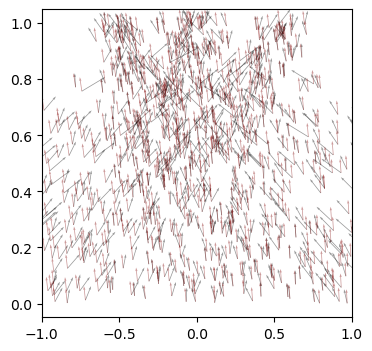

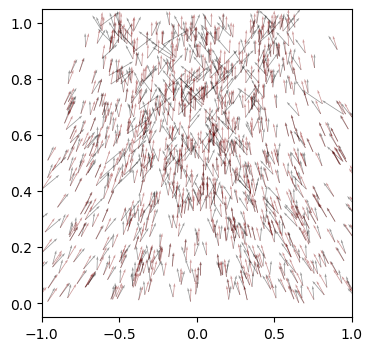

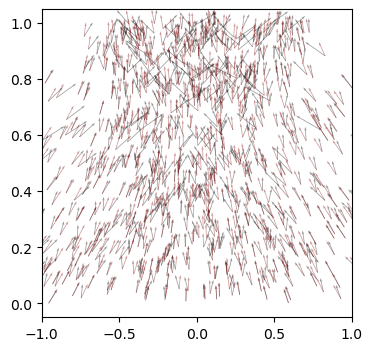

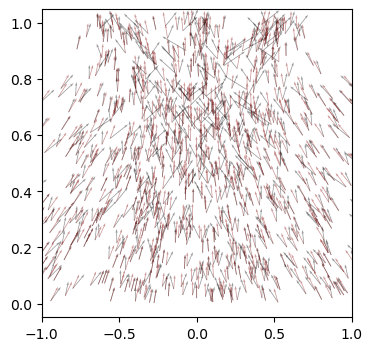

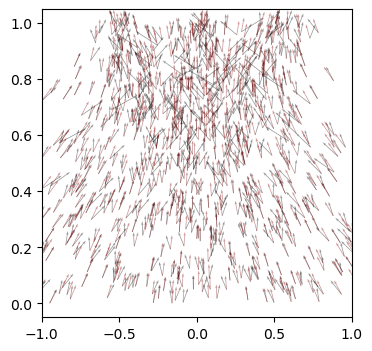

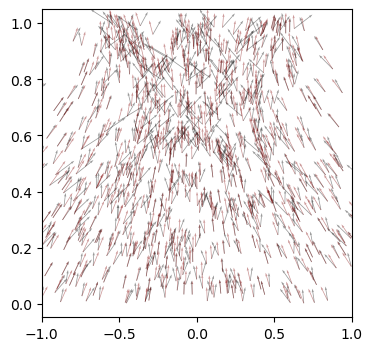

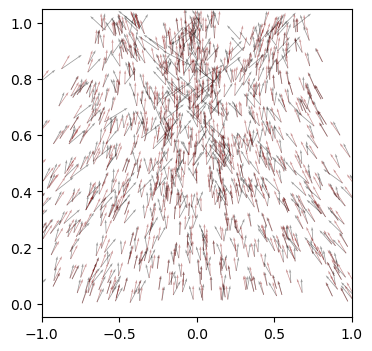

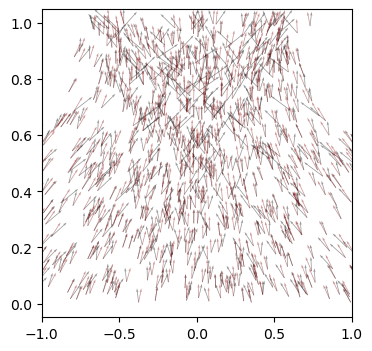

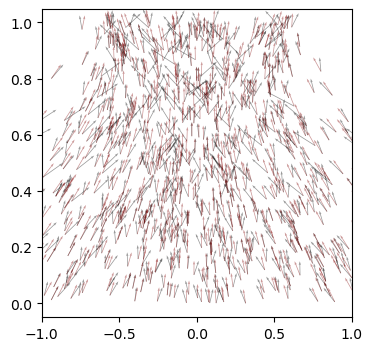

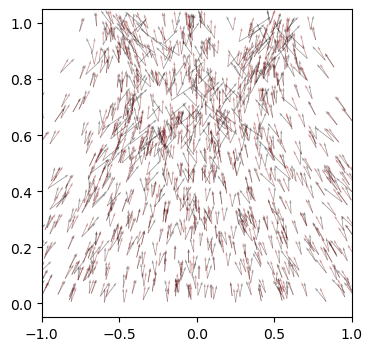

In [78]:
model = mlp()
model = train(model)

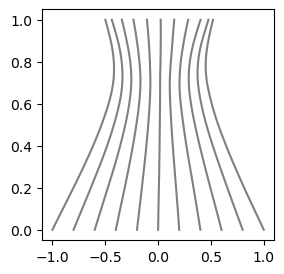

In [81]:
tint = np.linspace(0.0,1.0)
xint = odeint(lambda t, x:model(torch.cat([x,torch.full(x.shape, t.item())], dim=-1).float()).detach(), torch.tensor(np.linspace(-1,1,11).reshape(-1, 1)), torch.tensor(tint))
xint, tint = np.broadcast_arrays(xint, tint.reshape(-1,1,1))
plt.plot(xint[...,0], tint[...,0], c='grey')
plt.gcf().set_size_inches(3,3)

/tmp/ipykernel_14003/3784739338.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  xint = odeint(lambda t,x: model(torch.cat([x,torch.full(x.shape, t.item())],dim=-1).float()).detach(), noise, torch.tensor(tint))


(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  2.,
         1.,  3.,  4.,  7.,  5., 12., 10., 18., 23., 25., 28., 26., 23.,
        15., 23., 10., 14., 16.,  9., 10., 12., 13., 21., 13., 12., 23.,
        10., 11., 14., 19.,  8., 14., 10., 11.,  8.,  8.,  8., 12., 14.,
        12., 11., 17., 12.,  5., 13.,  8., 11., 12., 11., 11.,  7., 11.,
        10., 11.,  8., 11., 16.,  8., 11., 15., 23., 20., 31., 39., 19.,
        21., 16., 18., 15., 12.,  7., 10.,  3.,  3.,  2.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  1.,  0.,  1.,  0.]),
 array([-1.  , -0.98, -0.96, -0.94, -0.92, -0.9 , -0.88, -0.86, -0.84,
        -0.82, -0.8 , -0.78, -0.76, -0.74, -0.72, -0.7 , -0.68, -0.66,
        -0.64, -0.62, -0.6 , -0.58, -0.56, -0.54, -0.52, -0.5 , -0.48,
        -0.46, -0.44, -0.42, -0.4 , -0.38, -0.36, -0.34, -0.32, -0.3 ,
        -0.28, -0.26, -0.24, -0.22, -0.2 , -0.18, -0.16, -0.14, -0.12,
        -0.1 , -0.08, -0.06, -0.04, -0.02,  0.  ,  0.02,  0.04,  0.06,
        

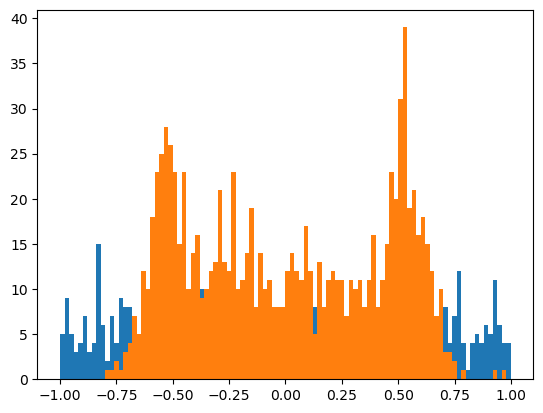

In [88]:
tint = torch.tensor([0.0,1.0], dtype=torch.float32)
noise = torch.randn(1000,1)
xint = odeint(lambda t,x: model(torch.cat([x,torch.full(x.shape, t.item())],dim=-1).float()).detach(), noise, torch.tensor(tint))
bins = np.linspace(-1,1,101)
plt.hist(xint[0,::,-1].detach(), bins = bins)
plt.hist(xint[-1,::,-1].detach(), bins = bins)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,  1.,
         1.,  5.,  5.,  5.,  9.,  4., 18., 21., 28., 26., 31., 27., 43.,
        22., 21., 25., 20., 15.,  8.,  9.,  4.,  7.,  4.,  0.,  5.,  2.,
         3.,  6.,  9.,  3., 12., 14., 17., 22., 24., 20., 24., 27., 27.,
        17., 23., 12., 22.,  6.,  5.,  5.,  5.,  1.,  0.,  1.,  2.,  2.,
         4., 10.,  5., 12., 16., 15., 16., 25., 31., 22., 23., 34., 23.,
        25., 17., 17.,  8.,  8.,  5.,  2.,  4.,  1.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]),
 array([-1.  , -0.98, -0.96, -0.94, -0.92, -0.9 , -0.88, -0.86, -0.84,
        -0.82, -0.8 , -0.78, -0.76, -0.74, -0.72, -0.7 , -0.68, -0.66,
        -0.64, -0.62, -0.6 , -0.58, -0.56, -0.54, -0.52, -0.5 , -0.48,
        -0.46, -0.44, -0.42, -0.4 , -0.38, -0.36, -0.34, -0.32, -0.3 ,
        -0.28, -0.26, -0.24, -0.22, -0.2 , -0.18, -0.16, -0.14, -0.12,
        -0.1 , -0.08, -0.06, -0.04, -0.02,  0.  ,  0.02,  0.04,  0.06,
        

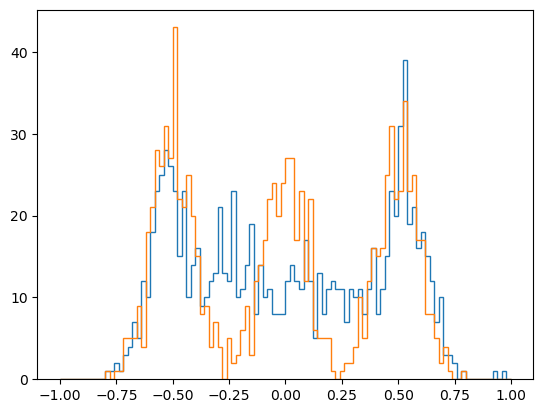

In [90]:
import sklearn.datasets as skld
plt.hist(xint[-1,::,-1].detach(), bins = bins, histtype = 'step')
plt.hist(np.random.normal(loc=np.random.choice([-0.5, 0, 0.5], size=1000), scale=0.1), bins = bins, histtype='step')
